# Практическая работа №5. Машинное обучение в анализе данных с использованием Spark MLlib

**Дисциплина:** Технологии и инструментарий анализа больших данных
**Тема:** Классификация, регрессия и кластеризация на собственных наборах данных в Spark MLlib

| | |
|---|---|
| **Выполнил:** | Тагин Никита |
| **Группа:** | ИКБО-61-23 |
| **Дата выполнения:** | 28.10.2026 |
| **Проверил:** | ст. преподаватель Приходько Н.А. |

**Цель работы** — пройти полный цикл применения машинного обучения средствами Spark MLlib: сформулировать задачу,
подготовить признаки без утечки целевой информации, разделить данные на train / valid / test, обучить несколько
моделей, сравнить их с базовым решением, подобрать гиперпараметры на valid и один раз оценить итоговую модель на test.

Код демонстрационной части методички не повторяется (по условию задания). Для каждой из трёх постановок выбран
**собственный набор данных** из предложенных преподавателем:

| Задача | Набор | Объекты | Целевой результат | Модели (+ базовое решение) |
|---|---|---|---|---|
| Классификация | Airline Satisfaction | 129 880 пассажиров × 22 | удовлетворён / не удовлетворён | LogisticRegression, RandomForest, GBT (+ мажоритарный класс, простое правило) |
| Регрессия | Podcast Dataset | 52 500 выпусков × 11 | время прослушивания, мин | LinearRegression, Polynomial + LR, RandomForest, GBT (+ среднее, правило «доля от длины») |
| Кластеризация | Dry Bean | 13 611 зёрен × 17 | группы похожих зёрен | KMeans, BisectingKMeans, GaussianMixture (+ правило «по площади») |

Каждая часть проходит обязательную последовательность самостоятельной работы (п. 8 методички):
1) загрузка и Spark-схема → 2) распределение ключей объектов и схема разбиения → 3) train / valid / test →
4) распределения предикторов и цели → 5) выбор признаков и точки утечки → 6) модели и подбор гиперпараметров на valid →
7) однократная оценка на test и визуализация. В конце — сохранение PipelineModel и ответы на контрольные вопросы.

## 0. Окружение и SparkSession

То же окружение, что и в практике №4: Python 3.13 в `~/.venvs/tiabd` (путь без кириллицы), JDK 21, PySpark 4.2,
дополнительно `matplotlib` для графиков. Служебный вывод JVM при запуске направляется в `spark_logs/jvm_stderr.log`.
Блокнот выполнен в веб-интерфейсе Jupyter Notebook (Chrome) командой *Restart Kernel and Run All*, отчёт выгружен
из Jupyter в WebPDF. Во всех случайных операциях используется `SEED = 42`.

In [1]:
import os, sys, platform, subprocess, contextlib, json, random
from pathlib import Path
from functools import reduce

JDK21 = "/Users/nikita/Library/Java/JavaVirtualMachines/jbr-21.0.6/Contents/Home"
if Path(JDK21).is_dir():
    os.environ["JAVA_HOME"] = JDK21
    os.environ["PATH"] = f"{JDK21}/bin:" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

SPARK_CONF = Path("spark_conf")
SPARK_CONF.mkdir(exist_ok=True)
(SPARK_CONF / "log4j2.properties").write_text(
    "rootLogger.level = error\n"
    "rootLogger.appenderRef.stdout.ref = console\n"
    "appender.console.type = Console\n"
    "appender.console.name = console\n"
    "appender.console.target = SYSTEM_ERR\n"
    "appender.console.layout.type = PatternLayout\n"
    "appender.console.layout.pattern = %d{yy/MM/dd HH:mm:ss} %p %c{1}: %m%n\n"
)
os.environ["SPARK_CONF_DIR"] = str(SPARK_CONF.resolve())

JVM_LOG = Path("spark_logs/jvm_stderr.log")

@contextlib.contextmanager
def jvm_stderr_to_file(path=JVM_LOG):
    # служебный вывод JVM при запуске -> файл; ошибки Spark приходят в Python как исключения
    path.parent.mkdir(exist_ok=True)
    sys.stderr.flush()
    saved = os.dup(2)
    with open(path, "ab") as f:
        os.dup2(f.fileno(), 2)
    try:
        yield
    finally:
        os.dup2(saved, 2)
        os.close(saved)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pyspark

from pyspark.sql import SparkSession, DataFrame, functions as F
from pyspark.sql.types import (StructType, StructField, StringType, IntegerType,
                               DoubleType, BooleanType)
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler,
                                Imputer, SQLTransformer, PolynomialExpansion, PCA)
from pyspark.ml.classification import (LogisticRegression, RandomForestClassifier,
                                       GBTClassifier)
from pyspark.ml.regression import (LinearRegression, RandomForestRegressor, GBTRegressor)
from pyspark.ml.clustering import KMeans, BisectingKMeans, GaussianMixture
from pyspark.ml.evaluation import (BinaryClassificationEvaluator, RegressionEvaluator,
                                   ClusteringEvaluator)
from pyspark.ml.functions import vector_to_array

SEED = 42
DATA = Path("data")
OUT = Path("results")
OUT.mkdir(exist_ok=True)

with jvm_stderr_to_file():
    spark = (
        SparkSession.builder
        .master("local[*]")
        .appName("Practice5_MLlib")
        .config("spark.driver.memory", "6g")
        .config("spark.sql.shuffle.partitions", "8")
        .config("spark.ui.showConsoleProgress", "false")
        .getOrCreate()
    )
spark.sparkContext.setLogLevel("ERROR")

java_ver = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0]
print("Python:", platform.python_version(), "| Java:", java_ver)
print("PySpark:", pyspark.__version__, "| pandas:", pd.__version__, "| matplotlib:", matplotlib.__version__)
print("Master:", spark.sparkContext.master, "| parallelism:", spark.sparkContext.defaultParallelism)

Python: 3.13.2 | Java: openjdk version "21.0.6" 2025-01-21
PySpark: 4.2.1 | pandas: 2.3.3 | matplotlib: 3.11.2
Master: local[*] | parallelism: 8


Оформление графиков: категориальные цвета берутся в фиксированном порядке (синий → оранжевый → бирюзовый),
непрерывные величины — одним оттенком от светлого к тёмному, сетка и оси приглушены. Ниже — общие функции:
стратифицированное разбиение, ROC/PR-кривые и скорректированный индекс Рэнда (ARI) для сравнения кластеров с классами.

In [2]:
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"     # категориальные слоты 1-3
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#9cc1ee", "#2a78d6", "#0f3d75"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": "#b8b7b2",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": matplotlib.cycler(color=[C1, C2, C3]),
    "lines.linewidth": 2, "legend.frameon": False,
})

def stratified_split(df, label, weights, seed=SEED):
    """randomSplit внутри каждого класса -> доли классов одинаковы во всех частях."""
    values = [r[0] for r in df.select(label).distinct().collect()]
    parts = [[] for _ in weights]
    for v in values:
        for i, p in enumerate(df.filter(F.col(label) == v).randomSplit(weights, seed)):
            parts[i].append(p)
    return [reduce(DataFrame.unionByName, ps) for ps in parts]

def roc_pr(y, s):
    """ROC- и PR-кривые по меткам y и score s (numpy)."""
    order = np.argsort(-s)
    y = y[order]
    tp = np.cumsum(y); fp = np.cumsum(1 - y)
    tpr = tp / y.sum(); fpr = fp / (1 - y).sum()
    precision = tp / (tp + fp)
    return np.r_[0, fpr], np.r_[0, tpr], np.r_[1, tpr], np.r_[precision[0], precision]

def best_threshold(y, s, grid=np.round(np.arange(0.05, 0.96, 0.01), 2)):
    rows = []
    for t in grid:
        p = (s >= t).astype(int)
        tp = int(((p == 1) & (y == 1)).sum()); fp = int(((p == 1) & (y == 0)).sum())
        fn = int(((p == 0) & (y == 1)).sum())
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        rows.append((t, prec, rec, f1))
    tab = pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1"])
    return tab, float(tab.loc[tab.f1.idxmax(), "threshold"])

def ari(labels_true, labels_pred):
    """Adjusted Rand Index по таблице сопряжённости."""
    ct = pd.crosstab(labels_true, labels_pred).values
    comb = lambda n: n * (n - 1) / 2
    sum_ij = comb(ct).sum()
    a = comb(ct.sum(axis=1)).sum(); b = comb(ct.sum(axis=0)).sum()
    n = comb(ct.sum())
    expected = a * b / n
    return (sum_ij - expected) / ((a + b) / 2 - expected)

def feature_names(prep_model, assembler_inputs):
    """Имена элементов итогового вектора: one-hot раскрывается по словарю StringIndexer."""
    labels = {}
    for st in prep_model.stages:
        if type(st).__name__ == "StringIndexerModel":
            for col, lab in zip(st.getOutputCols(), st.labelsArray):
                labels[col.replace("_idx", "_ohe")] = lab
    names = []
    for c in assembler_inputs:
        if c in labels:
            names += [f"{c.replace('_ohe', '')}={v}" for v in labels[c]]
        else:
            names.append(c)
    return names

# Часть A. Классификация: удовлетворённость пассажиров авиакомпании

**Постановка.** По анкете пассажира и параметрам рейса предсказать, будет ли он удовлетворён полётом
(`satisfaction = True`). Бизнес-смысл — заранее найти пассажиров с высоким риском неудовлетворённости.

## A.1. Загрузка и Spark-схема

In [3]:
AIR_COLS = [
    ("gender", StringType()), ("customer_type", StringType()), ("age", IntegerType()),
    ("travel_type", StringType()), ("travel_class", StringType()), ("flight_distance", IntegerType()),
    ("wifi", IntegerType()), ("time_convenient", IntegerType()), ("online_booking", IntegerType()),
    ("gate_location", IntegerType()), ("food_drink", IntegerType()), ("online_boarding", IntegerType()),
    ("seat_comfort", IntegerType()), ("entertainment", IntegerType()), ("onboard_service", IntegerType()),
    ("leg_room", IntegerType()), ("baggage", IntegerType()), ("checkin", IntegerType()),
    ("cleanliness", IntegerType()), ("dep_delay", DoubleType()), ("arr_delay", DoubleType()),
    ("satisfaction", BooleanType()),
]
air_schema = StructType([StructField(n, t, True) for n, t in AIR_COLS])

air = (spark.read.option("header", True).schema(air_schema)
       .csv(str(DATA / "Airline Satisfaction Data.csv"))
       .withColumn("label", F.col("satisfaction").cast("double"))
       .cache())

print("Строк:", air.count(), "| столбцов:", len(air.columns))
air.printSchema()
air.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in air.columns])\
   .toPandas().T.rename(columns={0: "nulls"}).query("nulls > 0")

Строк: 129880 | столбцов: 23
root
 |-- gender: string (nullable = true)
 |-- customer_type: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- travel_type: string (nullable = true)
 |-- travel_class: string (nullable = true)
 |-- flight_distance: integer (nullable = true)
 |-- wifi: integer (nullable = true)
 |-- time_convenient: integer (nullable = true)
 |-- online_booking: integer (nullable = true)
 |-- gate_location: integer (nullable = true)
 |-- food_drink: integer (nullable = true)
 |-- online_boarding: integer (nullable = true)
 |-- seat_comfort: integer (nullable = true)
 |-- entertainment: integer (nullable = true)
 |-- onboard_service: integer (nullable = true)
 |-- leg_room: integer (nullable = true)
 |-- baggage: integer (nullable = true)
 |-- checkin: integer (nullable = true)
 |-- cleanliness: integer (nullable = true)
 |-- dep_delay: double (nullable = true)
 |-- arr_delay: double (nullable = true)
 |-- satisfaction: boolean (nullable = true)
 |-- label: 

,nulls
arr_delay,393


**Вывод.** Файл прочитан по явной схеме: 129 880 строк, 22 исходных столбца плюс числовая метка `label`. Длинные англоязычные названия столбцов заменены короткими. Пропуски есть только в `arr_delay` — 393 строки (0,3 %), остальные поля заполнены.

## A.2. Распределение ключей объектов и схема разбиения

В наборе нет идентификатора пассажира или даты рейса. Проверяем, нет ли повторяющихся объектов (полных дублей),
которые при случайном разбиении попали бы и в train, и в test, и смотрим баланс классов.

In [4]:
n_air = air.count()
n_dup = n_air - air.dropDuplicates([c for c, _ in AIR_COLS]).count()
print("Полных дублей:", n_dup)

air.groupBy("satisfaction").count()\
   .withColumn("share_%", F.round(F.col("count") / n_air * 100, 2)).show()

Полных дублей: 0
+------------+-----+-------+
|satisfaction|count|share_%|
+------------+-----+-------+
|        true|56428|  43.45|
|       false|73452|  56.55|
+------------+-----+-------+



**Вывод.** Полных дублей нет, идентификаторов и дат тоже нет, поэтому каждая строка — независимый пассажир, и случайное разбиение допустимо. Классы умеренно несбалансированы: 43,45 % удовлетворённых и 56,55 % неудовлетворённых. Поэтому разбиение стратифицировано, а помимо accuracy используются PR-AUC и F1.

## A.3. Train / valid / test

Пассажиры — независимые объекты без времени, поэтому используется **стратифицированное случайное разбиение**
70 / 15 / 15 с фиксированным seed: доля удовлетворённых одинакова во всех частях. Все преобразования (словари
категорий, масштабирование) обучаются только на train; valid — для выбора модели, гиперпараметров и порога;
test используется один раз в конце.

In [5]:
air_train, air_valid, air_test = [d.cache() for d in stratified_split(air, "satisfaction", [0.70, 0.15, 0.15])]
pd.DataFrame([
    {"часть": name, "строк": d.count(), "доля satisfied, %": round(d.agg(F.avg("label")).first()[0] * 100, 2)}
    for name, d in [("train", air_train), ("valid", air_valid), ("test", air_test)]
])

,часть,строк,"доля satisfied, %"
0,train,91209,43.46
1,valid,19330,43.41
2,test,19341,43.44


## A.4. Распределения предикторов и целевой переменной

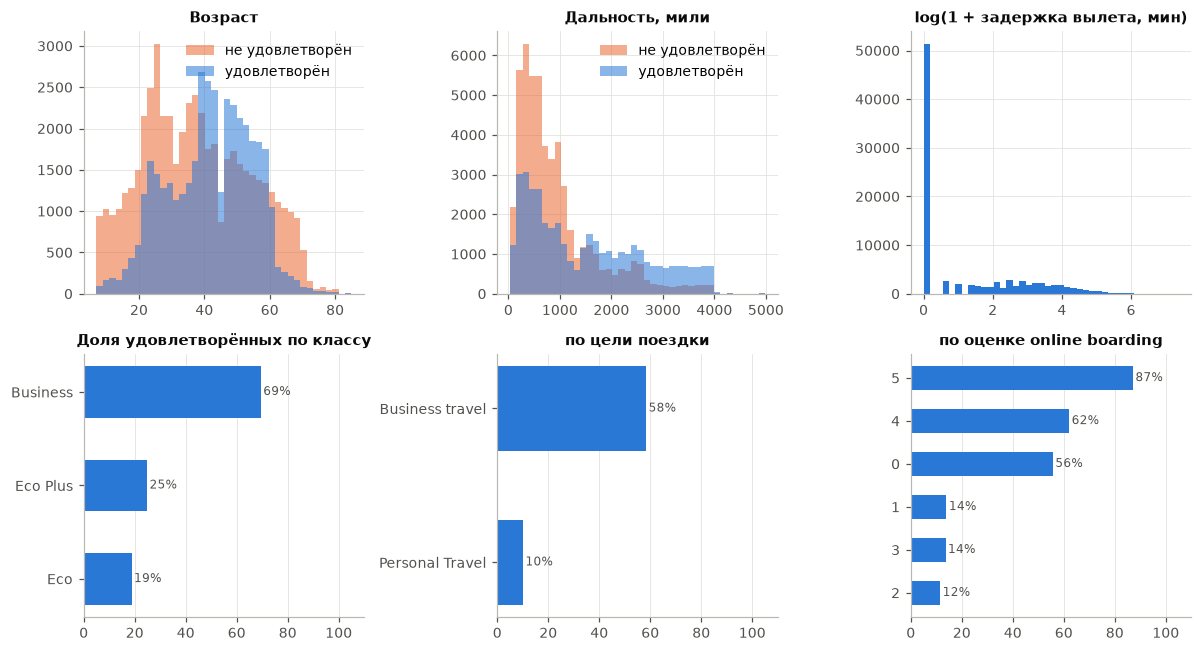

Доля задержек вылета = 0: 56.3 %


In [6]:
air_pd = air_train.select("age", "flight_distance", "dep_delay", "travel_type", "travel_class",
                          "customer_type", "online_boarding", "wifi", "entertainment", "label").toPandas()

fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, col, title in [(axes[0, 0], "age", "Возраст"), (axes[0, 1], "flight_distance", "Дальность, мили")]:
    for v, c, lab in [(0, C2, "не удовлетворён"), (1, C1, "удовлетворён")]:
        ax.hist(air_pd.loc[air_pd.label == v, col], bins=40, alpha=0.55, color=c, label=lab)
    ax.set_title(title); ax.legend()
ax = axes[0, 2]
ax.hist(np.log1p(air_pd.dep_delay), bins=40, color=C1)
ax.set_title("log(1 + задержка вылета, мин)")
for ax, col, title in [(axes[1, 0], "travel_class", "Доля удовлетворённых по классу"),
                       (axes[1, 1], "travel_type", "по цели поездки"),
                       (axes[1, 2], "online_boarding", "по оценке online boarding")]:
    s = air_pd.groupby(col).label.mean().sort_values() * 100
    ax.barh(s.index.astype(str), s.values, color=C1, height=0.55)
    for i, v in enumerate(s.values):
        ax.text(v + 1, i, f"{v:.0f}%", va="center", color=INK2, fontsize=8)
    ax.set_title(title); ax.set_xlim(0, 110); ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

print("Доля задержек вылета = 0:", round((air_pd.dep_delay == 0).mean() * 100, 1), "%")

**Вывод.** Стратификация сработала: доля удовлетворённых во всех частях 43,4–43,5 %. Сильнее всего удовлетворённость зависит от класса (Business — 69 %, Eco — 19 %) и цели поездки (деловая — 58 %, личная — 10 %). Среди оценок выделяется online boarding: при оценках 4–5 удовлетворены 62–87 % пассажиров, при оценках 1–3 — 12–14 %. Удовлетворённых больше среди пассажиров 40–60 лет и на дальних рейсах (больше 1 500 миль). Задержки распределены с сильной правой асимметрией: у 56 % рейсов задержки нет вовсе, поэтому используется `log1p`.

## A.5. Выбор предикторов и точки возможной утечки

* **Оценки сервиса (14 признаков, 0–5)** заполняются в той же анкете, что и целевая `satisfaction`. Если прогноз
  нужен **до опроса** (например, чтобы заранее работать с недовольными), использовать их нельзя — это утечка
  будущей информации. Поэтому строятся два набора признаков:
  * `PRE` — «до опроса»: пол, тип клиента, возраст, цель поездки, класс, дальность, задержки;
  * `FULL` — «после опроса»: `PRE` + 14 оценок (задача — объяснить удовлетворённость по анкете).
* Значение 0 в оценках означает «не оценено»; оставлено числом (отдельная градация шкалы).
* `arr_delay` пропущена у 393 строк — заполняется значением `dep_delay` той же строки (задержки прилёта и вылета
  почти совпадают); правило не использует целевую переменную и других строк. Задержки логарифмируются (`log1p`).
* Категории кодируются `StringIndexer` + `OneHotEncoder`, вектор масштабируется `StandardScaler` (нужно для LR).

In [7]:
AIR_CAT = ["gender", "customer_type", "travel_type", "travel_class"]
AIR_NUM_PRE = ["age", "flight_distance", "log_dep_delay", "log_arr_delay"]
AIR_RATINGS = ["wifi", "time_convenient", "online_booking", "gate_location", "food_drink",
               "online_boarding", "seat_comfort", "entertainment", "onboard_service",
               "leg_room", "baggage", "checkin", "cleanliness"]

def air_prep(numeric):
    inputs = [c + "_ohe" for c in AIR_CAT] + numeric
    stages = [
        SQLTransformer(statement=
            "SELECT *, log1p(dep_delay) AS log_dep_delay, "
            "log1p(coalesce(arr_delay, dep_delay)) AS log_arr_delay FROM __THIS__"),
        StringIndexer(inputCols=AIR_CAT, outputCols=[c + "_idx" for c in AIR_CAT], handleInvalid="keep"),
        OneHotEncoder(inputCols=[c + "_idx" for c in AIR_CAT], outputCols=[c + "_ohe" for c in AIR_CAT]),
        VectorAssembler(inputCols=inputs, outputCol="raw_features"),
        StandardScaler(inputCol="raw_features", outputCol="features"),
    ]
    return Pipeline(stages=stages), inputs

AIR_SETS = {"PRE": AIR_NUM_PRE, "FULL": AIR_NUM_PRE + AIR_RATINGS}
air_prep_models, air_inputs, air_tr, air_va = {}, {}, {}, {}
for name, num in AIR_SETS.items():
    pipe, inputs = air_prep(num)
    pm = pipe.fit(air_train)                       # обучается только на train
    air_prep_models[name], air_inputs[name] = pm, inputs
    air_tr[name] = pm.transform(air_train).select("features", "label").cache()
    air_va[name] = pm.transform(air_valid).select("features", "label").cache()
    print(f"{name}: признаков в векторе = {len(feature_names(pm, inputs))}")

PRE: признаков в векторе = 13
FULL: признаков в векторе = 26


## A.6. Модели, базовые решения и подбор гиперпараметров на valid

* **Базовые решения:** мажоритарный класс («никто не удовлетворён», ROC-AUC = 0,5) и простое правило
  «удовлетворён, если поездка деловая и класс Business» (из графиков п. A.4).
* **Модели:** LogisticRegression (`regParam`), RandomForest (`maxDepth`), GBT (`maxDepth`).
  Критерий выбора — **PR-AUC на valid** (классы не сбалансированы, важна точность положительного класса);
  ROC-AUC выводится рядом.

In [8]:
ev_roc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
ev_pr = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

def rule_score(df):
    return df.withColumn("rawPrediction",
        ((F.col("travel_type") == "Business travel") & (F.col("travel_class") == "Business")).cast("double"))

base_rows = []
for name, d in [("Мажоритарный класс", air_valid.withColumn("rawPrediction", F.lit(0.0))),
                ("Правило Business+Business", rule_score(air_valid))]:
    base_rows.append({"набор": "—", "модель": name, "параметры": "—",
                      "ROC-AUC": round(ev_roc.evaluate(d), 4), "PR-AUC": round(ev_pr.evaluate(d), 4)})

AIR_GRID = [
    ("LogReg", lambda v: LogisticRegression(regParam=v, elasticNetParam=0.0, maxIter=100), "regParam", [0.0, 0.01, 0.1]),
    ("RandomForest", lambda v: RandomForestClassifier(numTrees=80, maxDepth=v, seed=SEED), "maxDepth", [6, 10, 14, 18]),
    ("GBT", lambda v: GBTClassifier(maxIter=60, maxDepth=v, stepSize=0.1, seed=SEED), "maxDepth", [3, 5, 7]),
]

air_runs = []
for set_name in ["PRE", "FULL"]:
    for model_name, make, pname, values in AIR_GRID:
        for v in values:
            m = make(v).fit(air_tr[set_name])
            pv = m.transform(air_va[set_name])
            air_runs.append({"набор": set_name, "модель": model_name, "параметры": f"{pname}={v}",
                             "ROC-AUC": round(ev_roc.evaluate(pv), 4), "PR-AUC": round(ev_pr.evaluate(pv), 4),
                             "_model": m})

air_valid_table = pd.DataFrame(base_rows + [{k: v for k, v in r.items() if k != "_model"} for r in air_runs])
air_valid_table

,набор,модель,параметры,ROC-AUC,PR-AUC
0,—,Мажоритарный класс,—,0.5000,0.4341
1,—,Правило Business+Business,—,0.7670,0.6869
2,PRE,LogReg,regParam=0.0,0.8466,0.7729
3,PRE,LogReg,regParam=0.01,0.8462,0.7748
4,PRE,LogReg,regParam=0.1,0.8435,0.7704
5,PRE,RandomForest,maxDepth=6,0.8594,0.8016
6,PRE,RandomForest,maxDepth=10,0.8663,0.8060
7,PRE,RandomForest,maxDepth=14,0.8676,0.8109
8,PRE,RandomForest,maxDepth=18,0.8669,0.8097
9,PRE,GBT,maxDepth=3,0.8668,0.8108


In [9]:
runs = pd.DataFrame(air_runs)
best_air = {}
for set_name in ["PRE", "FULL"]:
    for model_name in ["LogReg", "RandomForest", "GBT"]:
        sub = runs[(runs["набор"] == set_name) & (runs["модель"] == model_name)]
        best_air[(set_name, model_name)] = sub.loc[sub["PR-AUC"].idxmax()]

summary = pd.DataFrame([{"набор": k[0], "модель": k[1], "лучшие параметры": r["параметры"],
                         "ROC-AUC valid": r["ROC-AUC"], "PR-AUC valid": r["PR-AUC"]}
                        for k, r in best_air.items()])
display(summary)

FINAL_AIR = {s: max(["LogReg", "RandomForest", "GBT"], key=lambda m: best_air[(s, m)]["PR-AUC"])
             for s in ["PRE", "FULL"]}
print("Лучшая модель по PR-AUC на valid:", FINAL_AIR)

,набор,модель,лучшие параметры,ROC-AUC valid,PR-AUC valid
0,PRE,LogReg,regParam=0.01,0.8462,0.7748
1,PRE,RandomForest,maxDepth=14,0.8676,0.8109
2,PRE,GBT,maxDepth=3,0.8668,0.8108
3,FULL,LogReg,regParam=0.0,0.9280,0.9318
4,FULL,RandomForest,maxDepth=18,0.9936,0.9927
5,FULL,GBT,maxDepth=7,0.9922,0.9910


Лучшая модель по PR-AUC на valid: {'PRE': 'RandomForest', 'FULL': 'RandomForest'}


### Выбор порога решения на valid

Модель возвращает вероятность; порог 0,5 не обязан быть лучшим. Порог выбирается **только на valid** по максимуму F1
и затем фиксируется для test.

Порог по максимуму F1 на valid: 0.51


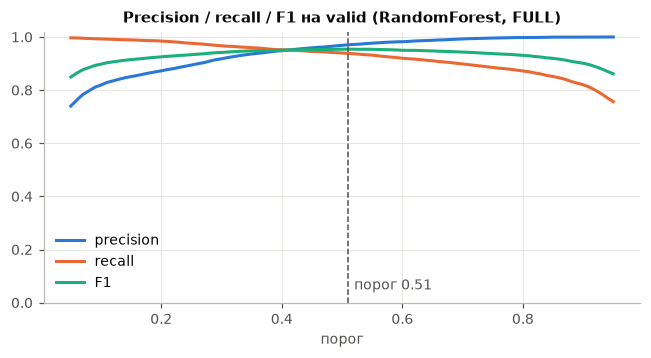

,threshold,precision,recall,f1
46,0.51,0.9707,0.938,0.9541


In [10]:
def scores(model, df):
    p = model.transform(df).select("label", vector_to_array("probability")[1].alias("score")).toPandas()
    return p.label.values.astype(int), p.score.values

y_va, s_va = scores(best_air[("FULL", FINAL_AIR["FULL"])]["_model"], air_va["FULL"])
thr_tab, AIR_THRESHOLD = best_threshold(y_va, s_va)
print("Порог по максимуму F1 на valid:", AIR_THRESHOLD)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(thr_tab.threshold, thr_tab.precision, color=C1, label="precision")
ax.plot(thr_tab.threshold, thr_tab.recall, color=C2, label="recall")
ax.plot(thr_tab.threshold, thr_tab.f1, color=C3, label="F1")
ax.axvline(AIR_THRESHOLD, color=INK2, lw=1, ls="--")
ax.text(AIR_THRESHOLD + 0.01, 0.05, f"порог {AIR_THRESHOLD:.2f}", color=INK2)
ax.set_xlabel("порог"); ax.set_title(f"Precision / recall / F1 на valid ({FINAL_AIR['FULL']}, FULL)")
ax.legend(loc="lower left"); ax.set_ylim(0, 1.02); plt.show()
thr_tab.iloc[[thr_tab.f1.idxmax()]].round(4)

**Вывод.** Даже без анкеты (набор PRE) модели заметно лучше базовых решений. Лучшая по PR-AUC — RandomForest с `maxDepth=14`: PR-AUC 0,811 и ROC-AUC 0,868 на valid, против 0,687 / 0,767 у правила Business+Business. Оценки сервиса (набор FULL) поднимают качество до PR-AUC 0,993 и ROC-AUC 0,994 у RandomForest с `maxDepth=18`. Это и есть разница между прогнозом «до опроса» и объяснением удовлетворённости «по анкете». Деревья заметно сильнее логистической регрессии (0,932 на FULL): зависимость от оценок нелинейная и содержит взаимодействия. Лучшая глубина 18 — снова на границе сетки, но прирост от 14 к 18 уже мал (+0,001). Порог по максимуму F1 на valid — 0,51 (F1 = 0,954), он почти совпадает со стандартным 0,5, потому что модель хорошо разделяет классы.

## A.7. Однократная оценка на test и визуализация

Финальные модели обучены на train (подготовка признаков — тоже на train), порог выбран на valid.
На test оцениваются базовые решения, лучшая модель «до опроса» и лучшая модель «после опроса».

In [11]:
def cls_metrics(y, s, thr):
    p = (s >= thr).astype(int)
    tp = ((p == 1) & (y == 1)).sum(); fp = ((p == 1) & (y == 0)).sum()
    fn = ((p == 0) & (y == 1)).sum(); tn = ((p == 0) & (y == 0)).sum()
    prec = tp / (tp + fp) if tp + fp else 0; rec = tp / (tp + fn)
    return {"accuracy": (tp + tn) / len(y), "precision": prec, "recall": rec,
            "F1": 2 * prec * rec / (prec + rec) if prec + rec else 0}

test_rows, curves = [], {}
y_rule = air_test.select("label").toPandas().label.values.astype(int)
for name, d in [("Мажоритарный класс", air_test.withColumn("rawPrediction", F.lit(0.0))),
                ("Правило Business+Business", rule_score(air_test))]:
    s = d.select("rawPrediction").toPandas().rawPrediction.values
    test_rows.append({"решение": name, "порог": 0.5, "ROC-AUC": ev_roc.evaluate(d), "PR-AUC": ev_pr.evaluate(d),
                      **cls_metrics(y_rule, s, 0.5)})

for set_name in ["PRE", "FULL"]:
    for model_name in sorted({FINAL_AIR[set_name], "LogReg"}):
        m = best_air[(set_name, model_name)]["_model"]
        te = air_prep_models[set_name].transform(air_test)
        pred = m.transform(te)
        y, s = scores(m, te)
        thr = AIR_THRESHOLD if (set_name, model_name) == ("FULL", FINAL_AIR["FULL"]) else 0.5
        curves[f"{model_name} ({set_name})"] = roc_pr(y, s)
        test_rows.append({"решение": f"{model_name} ({set_name})", "порог": thr,
                          "ROC-AUC": ev_roc.evaluate(pred), "PR-AUC": ev_pr.evaluate(pred),
                          **cls_metrics(y, s, thr)})

air_test_table = pd.DataFrame(test_rows).round(4)
air_test_table

,решение,порог,ROC-AUC,PR-AUC,accuracy,precision,recall,F1
0,Мажоритарный класс,0.50,0.5000,0.4344,0.5656,0.0000,0.0000,0.0000
1,Правило Business+Business,0.50,0.7664,0.6847,0.7670,0.7185,0.7621,0.7396
2,LogReg (PRE),0.50,0.8451,0.7743,0.7898,0.7461,0.7823,0.7638
3,RandomForest (PRE),0.50,0.8658,0.8071,0.8055,0.7660,0.7950,0.7803
4,LogReg (FULL),0.50,0.9279,0.9319,0.8755,0.8726,0.8355,0.8536
5,RandomForest (FULL),0.51,0.9935,0.9925,0.9601,0.9696,0.9375,0.9533


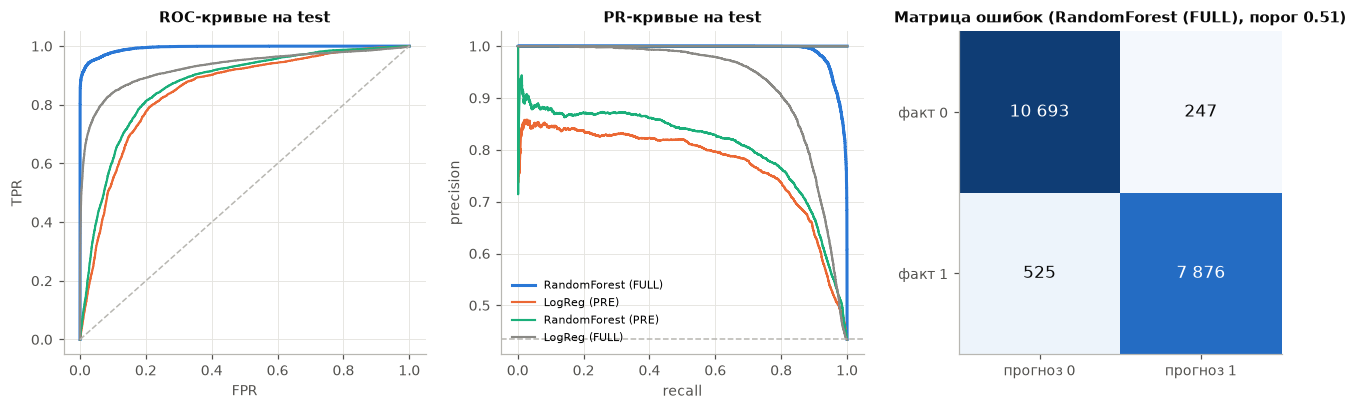

In [12]:
best_key = f"{FINAL_AIR['FULL']} (FULL)"
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
order = [best_key] + [k for k in curves if k != best_key]
colors = dict(zip(order, [C1, C2, C3, "#8a8985"]))
for k in order:
    fpr, tpr, rec, prec = curves[k]
    axes[0].plot(fpr, tpr, color=colors[k], label=k, lw=2 if k == best_key else 1.4)
    axes[1].plot(rec, prec, color=colors[k], label=k, lw=2 if k == best_key else 1.4)
axes[0].plot([0, 1], [0, 1], color="#b8b7b2", lw=1, ls="--")
axes[0].set_title("ROC-кривые на test"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
axes[1].axhline(y_rule.mean(), color="#b8b7b2", lw=1, ls="--")
axes[1].set_title("PR-кривые на test"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision")
axes[1].legend(loc="lower left", fontsize=7.5)

m = best_air[("FULL", FINAL_AIR["FULL"])]["_model"]
y, s = scores(m, air_prep_models["FULL"].transform(air_test))
p = (s >= AIR_THRESHOLD).astype(int)
cm = np.array([[((y == a) & (p == b)).sum() for b in (0, 1)] for a in (0, 1)])
axes[2].imshow(cm, cmap=SEQ)
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, f"{cm[i, j]:,}".replace(",", " "), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else INK, fontsize=11)
axes[2].set_xticks([0, 1], ["прогноз 0", "прогноз 1"]); axes[2].set_yticks([0, 1], ["факт 0", "факт 1"])
axes[2].grid(False); axes[2].set_title(f"Матрица ошибок ({best_key}, порог {AIR_THRESHOLD:.2f})")
fig.tight_layout(); plt.show()

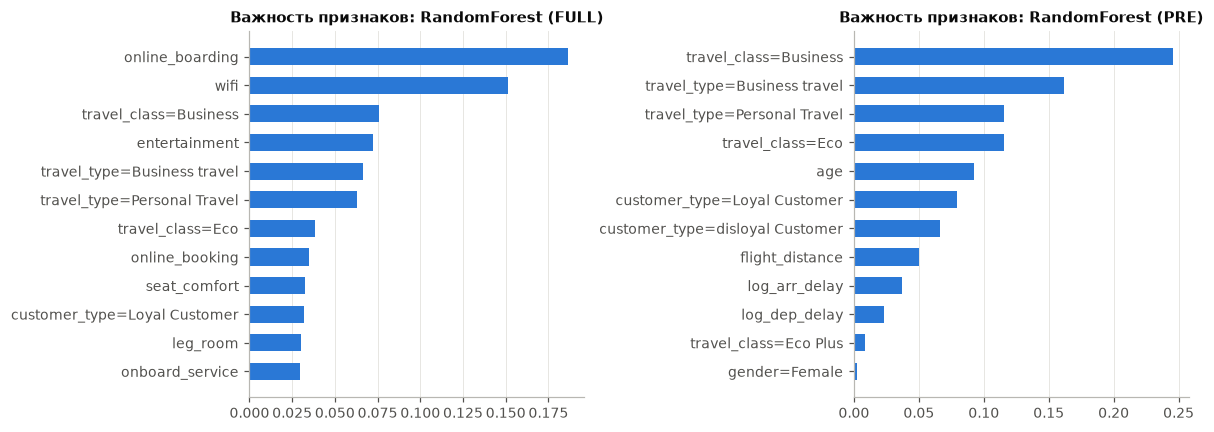

In [13]:
def importances(model, prep_model, inputs, top=12):
    names = feature_names(prep_model, inputs)
    if hasattr(model, "featureImportances"):
        vals = model.featureImportances.toArray()
    else:
        vals = np.abs(model.coefficients.toArray())
    return pd.Series(vals, index=names).sort_values(ascending=False).head(top)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, set_name in zip(axes, ["FULL", "PRE"]):
    mname = FINAL_AIR[set_name]
    imp = importances(best_air[(set_name, mname)]["_model"], air_prep_models[set_name], air_inputs[set_name])
    ax.barh(imp.index[::-1], imp.values[::-1], color=C1, height=0.6)
    ax.set_title(f"Важность признаков: {mname} ({set_name})"); ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

**Вывод.** Метрики на test совпадают с valid, переобучения на этапе выбора нет. Лучшая модель (RandomForest, FULL, порог 0,51) даёт ROC-AUC 0,9935, PR-AUC 0,9925, accuracy 0,960 и F1 0,953. Из 19 341 пассажира ошибочно классифицированы 772: 247 ложных «удовлетворён» и 525 пропущенных удовлетворённых. Лучшая модель «до опроса» (RandomForest, PRE) — ROC-AUC 0,866, F1 0,780 — превосходит правило (F1 0,740) и мажоритарный класс (F1 = 0). У полной модели главные признаки — `online_boarding` и `wifi`, у модели «до опроса» — класс и цель поездки. Сохранённая и заново загруженная модель воспроизводит ROC-AUC 0,9935.

# Часть B. Регрессия: время прослушивания выпуска подкаста

**Постановка.** По характеристикам выпуска, известным в момент публикации (длительность, жанр, популярность ведущего
и гостя, число рекламных вставок, день и время публикации, тональность), предсказать среднее время прослушивания
`Listening_Time_minutes`. Бизнес-смысл — оценить вовлечённость аудитории до выхода выпуска.

## B.1. Загрузка и Spark-схема

In [14]:
POD_COLS = [
    ("podcast", StringType()), ("episode_title", StringType()), ("length", DoubleType()),
    ("genre", StringType()), ("host_pop", DoubleType()), ("pub_day", StringType()),
    ("pub_time", StringType()), ("guest_pop", DoubleType()), ("ads", DoubleType()),
    ("sentiment", StringType()), ("listen", DoubleType()),
]
pod_raw = (spark.read.option("header", True)
           .schema(StructType([StructField(n, t, True) for n, t in POD_COLS]))
           .csv(str(DATA / "podcast_dataset.csv")))

n_raw = pod_raw.count()
print("Строк:", n_raw, "| столбцов:", len(pod_raw.columns))
pod_raw.printSchema()
pd.DataFrame({"пропусков": pod_raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c)
                                           for c in pod_raw.columns]).toPandas().iloc[0]}).query("пропусков > 0")

Строк: 52500 | столбцов: 11
root
 |-- podcast: string (nullable = true)
 |-- episode_title: string (nullable = true)
 |-- length: double (nullable = true)
 |-- genre: string (nullable = true)
 |-- host_pop: double (nullable = true)
 |-- pub_day: string (nullable = true)
 |-- pub_time: string (nullable = true)
 |-- guest_pop: double (nullable = true)
 |-- ads: double (nullable = true)
 |-- sentiment: string (nullable = true)
 |-- listen: double (nullable = true)



,пропусков
length,5246
guest_pop,5258
listen,5395


In [15]:
n_dedup = pod_raw.dropDuplicates().count()
pod = (pod_raw.dropDuplicates()
       .filter(F.col("listen").isNotNull())
       .withColumn("episode_num", F.regexp_extract("episode_title", r"(\d+)", 1).cast("int"))
       .cache())
print("Полных дублей:", n_raw - n_dedup)
print("Строк без целевой переменной (после удаления дублей):", n_dedup - pod.count())
print("Осталось для моделирования:", pod.count())

Полных дублей: 2500
Строк без целевой переменной (после удаления дублей): 5132
Осталось для моделирования: 44868


**Вывод.** Из 52 500 строк удалено 2 500 полных дублей: иначе одинаковые выпуски могли бы попасть и в train, и в test. Ещё 5 132 строки без целевой переменной исключены: учиться на них нельзя, а заполнять цель — значит выдумывать ответ. Для моделирования осталось 44 868 выпусков. Пропуски в признаках `length` и `guest_pop` (по ~10 %) сохранены и обрабатываются внутри Pipeline.

## B.2. Распределение ключей объектов и схема разбиения

Объект — выпуск подкаста; ключ группы — название подкаста. Если выпуски одного подкаста окажутся и в train, и в test,
модель может «узнавать» подкаст, и оценка на test будет завышена для сценария «новый подкаст».

In [16]:
per_pod = pod.groupBy("podcast").agg(F.count("*").alias("episodes"),
                                    F.countDistinct("genre").alias("genres"),
                                    F.round(F.avg("listen"), 1).alias("avg_listen"))
pp = per_pod.toPandas()
print("Подкастов:", len(pp), "| выпусков на подкаст: min", pp.episodes.min(), "/ median",
      int(pp.episodes.median()), "/ max", pp.episodes.max())
print("Жанров у одного подкаста (min / max):", pp.genres.min(), "/", pp.genres.max())
print("Номеров эпизодов:", pod.select("episode_num").distinct().count())
pp.sort_values("episodes", ascending=False).head(5)

Подкастов: 48 | выпусков на подкаст: min 817 / median 938 / max 1013
Жанров у одного подкаста (min / max): 1 / 1
Номеров эпизодов: 100


,podcast,episodes,genres,avg_listen
32,Fitness First,1013,1,44.8
13,Style Guide,991,1,43.8
26,Educational Nuggets,989,1,45.7
21,Business Briefs,986,1,46.3
41,Melody Mix,979,1,46.7


**Вывод.** 48 подкастов, у каждого от 817 до 1 013 выпусков, у каждого подкаста ровно один жанр. Группы крупные и одинаковые по размеру, поэтому разбиение по подкастам даёт части разумного объёма. Номер эпизода принимает 100 значений, это обычный числовой признак, а не ключ объекта.

## B.3. Train / valid / test по группам-подкастам

Разбиение **по подкастам** (group split): список из 48 подкастов перемешивается с `SEED` и делится на 34 / 7 / 7.
Все выпуски одного подкаста попадают ровно в одну часть, поэтому test проверяет перенос на подкасты, которых
модель не видела. Данные не являются временным рядом (даты публикации нет), поэтому временная схема не нужна.

In [17]:
podcasts = sorted(pp.podcast)
random.Random(SEED).shuffle(podcasts)
POD_SPLIT = {"train": podcasts[:34], "valid": podcasts[34:41], "test": podcasts[41:]}
pod_train, pod_valid, pod_test = [pod.filter(F.col("podcast").isin(POD_SPLIT[k])).cache()
                                  for k in ["train", "valid", "test"]]
pd.DataFrame([{"часть": k, "подкастов": len(v), "выпусков": d.count(),
               "среднее listen": round(d.agg(F.avg("listen")).first()[0], 2)}
              for (k, v), d in zip(POD_SPLIT.items(), [pod_train, pod_valid, pod_test])])

,часть,подкастов,выпусков,среднее listen
0,train,34,31845,45.61
1,valid,7,6487,45.64
2,test,7,6536,45.11


## B.4. Распределения предикторов и целевой переменной

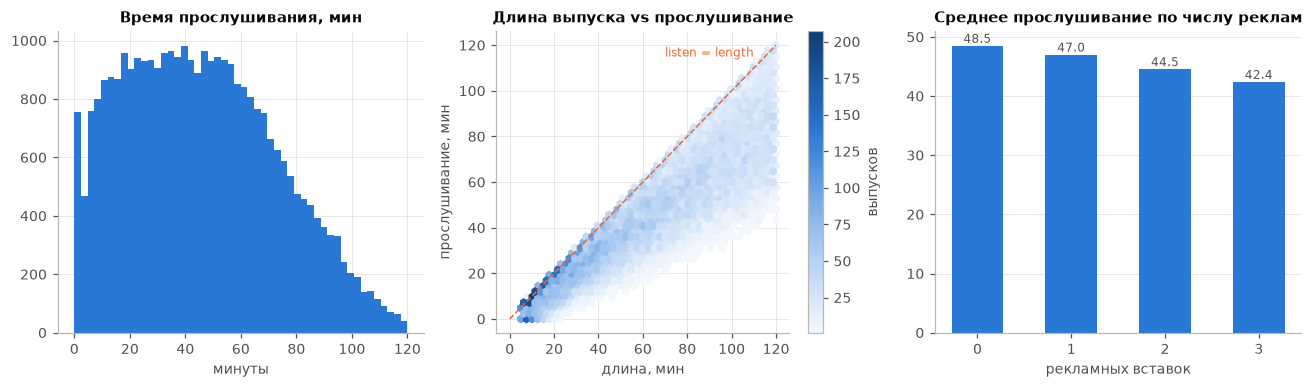

Пропуск длины выпуска в train: 10.0 %
Корреляция length–listen: 0.902
Доля listen > length: 0.0 %


In [18]:
pdf = pod_train.select("length", "listen", "host_pop", "guest_pop", "ads", "genre").toPandas()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].hist(pdf.listen, bins=50, color=C1)
axes[0].set_title("Время прослушивания, мин"); axes[0].set_xlabel("минуты")

ok = pdf.dropna(subset=["length"])
hb = axes[1].hexbin(ok.length, ok.listen, gridsize=45, cmap=SEQ, mincnt=1)
axes[1].plot([0, 120], [0, 120], color=C2, lw=1, ls="--")
axes[1].text(70, 115, "listen = length", color=C2, fontsize=8)
axes[1].set_title("Длина выпуска vs прослушивание"); axes[1].set_xlabel("длина, мин"); axes[1].set_ylabel("прослушивание, мин")
fig.colorbar(hb, ax=axes[1], label="выпусков")

s = (pdf.groupby("ads").listen.mean())
axes[2].bar(s.index.astype(int).astype(str), s.values, color=C1, width=0.55)
for i, v in enumerate(s.values):
    axes[2].text(i, v + 0.5, f"{v:.1f}", ha="center", color=INK2, fontsize=8)
axes[2].set_title("Среднее прослушивание по числу реклам"); axes[2].set_xlabel("рекламных вставок")
axes[2].grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

print("Пропуск длины выпуска в train:", round(pdf.length.isna().mean() * 100, 1), "%")
print("Корреляция length–listen:", round(ok[["length", "listen"]].corr().iloc[0, 1], 3))
print("Доля listen > length:", round((ok.listen > ok.length).mean() * 100, 2), "%")

**Вывод.** После разбиения 34 / 7 / 7 подкастов в частях 31 845 / 6 487 / 6 536 выпусков, средние значения цели близки (45,1–45,6 мин). Целевая переменная распределена от 0 до 120 минут. Главный предиктор — длина выпуска: корреляция 0,90, время прослушивания никогда не превышает длину (точки лежат под диагональю). Число рекламных вставок слабо снижает среднее время. Длина неизвестна у 10 % выпусков — от этого зависит, насколько точными могут быть прогнозы.

## B.5. Выбор предикторов и точки возможной утечки

* **Исключены:** `podcast` (при group split у новых подкастов нет обучающей статистики, признак не обобщается)
  и `episode_title` как текст; номер эпизода `episode_num` оставлен как числовой признак (известен до публикации).
* **Целевая не участвует в признаках:** никакие агрегаты `listen` (средние по подкасту, жанру) не считаются — это
  была бы прямая утечка; заполнение пропусков (`Imputer`, медиана) обучается только на train.
* **Пропуски:** `length` (≈10 %) и `guest_pop` (≈10 %, вероятно — выпуск без гостя) заполняются медианой train,
  а факт пропуска сохраняется флагами `length_missing`, `guest_missing` — так модель отличает «не знаем длину»
  от «средней длины».
* **Категории** `genre`, `pub_day`, `pub_time`, `sentiment` — `StringIndexer` + `OneHotEncoder`.

In [19]:
POD_CAT = ["genre", "pub_day", "pub_time", "sentiment"]
POD_NUM = ["length_imp", "host_pop", "guest_pop_imp", "ads", "episode_num", "length_missing", "guest_missing"]
POD_INPUTS = [c + "_ohe" for c in POD_CAT] + POD_NUM

def pod_prep(poly_degree=None):
    stages = [
        SQLTransformer(statement=
            "SELECT *, CAST(length IS NULL AS DOUBLE) AS length_missing, "
            "CAST(guest_pop IS NULL AS DOUBLE) AS guest_missing FROM __THIS__"),
        Imputer(inputCols=["length", "guest_pop"], outputCols=["length_imp", "guest_pop_imp"], strategy="median"),
        StringIndexer(inputCols=POD_CAT, outputCols=[c + "_idx" for c in POD_CAT], handleInvalid="keep"),
        OneHotEncoder(inputCols=[c + "_idx" for c in POD_CAT], outputCols=[c + "_ohe" for c in POD_CAT]),
        VectorAssembler(inputCols=POD_INPUTS, outputCol="raw_features"),
        StandardScaler(inputCol="raw_features", outputCol="scaled", withMean=True),
    ]
    if poly_degree:
        stages.append(PolynomialExpansion(degree=poly_degree, inputCol="scaled", outputCol="features"))
    else:
        stages.append(SQLTransformer(statement="SELECT *, scaled AS features FROM __THIS__"))
    return Pipeline(stages=stages)

pod_prep_models = {"linear": pod_prep().fit(pod_train), "poly2": pod_prep(2).fit(pod_train)}
pod_tr = {k: m.transform(pod_train).select("features", F.col("listen").alias("label")).cache()
          for k, m in pod_prep_models.items()}
pod_va = {k: m.transform(pod_valid).select("features", F.col("listen").alias("label")).cache()
          for k, m in pod_prep_models.items()}
for k, d in pod_tr.items():
    print(k, "— размер вектора:", len(d.first().features))

linear — размер вектора: 31
poly2 — размер вектора: 527


## B.6. Модели, базовые решения и подбор гиперпараметров на valid

* **Базовые решения:** (1) среднее `listen` по train для всех выпусков; (2) правило «доля от длины»:
  `listen ≈ k · length`, где `k` — медиана отношения `listen / length` на train (при неизвестной длине — среднее train).
* **Модели:** LinearRegression (`regParam`), полиномиальная регрессия 2-й степени (`PolynomialExpansion` + LR, `regParam`),
  RandomForestRegressor (`maxDepth`), GBTRegressor (`maxDepth`). Критерий выбора — **RMSE на valid**.

In [20]:
ev_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
ev_mae = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
ev_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

def reg_metrics(pred):
    return {"RMSE": ev_rmse.evaluate(pred), "MAE": ev_mae.evaluate(pred), "R2": ev_r2.evaluate(pred)}

MEAN_LISTEN = pod_train.agg(F.avg("listen")).first()[0]
RATIO_K = pod_train.filter(F.col("length").isNotNull())\
                   .select((F.col("listen") / F.col("length")).alias("r")).approxQuantile("r", [0.5], 0.001)[0]
print(f"Среднее listen (train) = {MEAN_LISTEN:.2f} мин; медиана listen/length = {RATIO_K:.3f}")

def baselines(df):
    d = df.withColumn("label", F.col("listen"))
    return {"Среднее train": d.withColumn("prediction", F.lit(MEAN_LISTEN)),
            "Правило k·length": d.withColumn("prediction",
                F.coalesce(F.col("length") * F.lit(RATIO_K), F.lit(MEAN_LISTEN)))}

POD_GRID = [
    ("LinearRegression", "linear", lambda v: LinearRegression(regParam=v, elasticNetParam=0.0), "regParam", [0.0, 0.1, 1.0]),
    ("Polynomial(2)+LR", "poly2", lambda v: LinearRegression(regParam=v, elasticNetParam=0.0), "regParam", [0.01, 0.1, 1.0]),
    ("RandomForest", "linear", lambda v: RandomForestRegressor(numTrees=60, maxDepth=v, seed=SEED), "maxDepth", [6, 10, 14]),
    ("GBT", "linear", lambda v: GBTRegressor(maxIter=60, maxDepth=v, stepSize=0.1, seed=SEED), "maxDepth", [3, 5, 7]),
]

pod_rows = [{"модель": n, "параметры": "—", **reg_metrics(d)} for n, d in baselines(pod_valid).items()]
pod_runs = []
for name, prep, make, pname, values in POD_GRID:
    for v in values:
        m = make(v).fit(pod_tr[prep])
        r = {"модель": name, "параметры": f"{pname}={v}", **reg_metrics(m.transform(pod_va[prep]))}
        pod_rows.append(r)
        pod_runs.append({**r, "_model": m, "_prep": prep})

pod_valid_table = pd.DataFrame(pod_rows).round(4)
pod_valid_table

Среднее listen (train) = 45.61 мин; медиана listen/length = 0.729


,модель,параметры,RMSE,MAE,R2
0,Среднее train,—,27.3161,22.8415,-0.0000
1,Правило k·length,—,14.0886,10.4841,0.7340
2,LinearRegression,regParam=0.0,13.7363,10.2663,0.7471
3,LinearRegression,regParam=0.1,13.7382,10.2661,0.7471
4,LinearRegression,regParam=1.0,13.7776,10.2959,0.7456
5,Polynomial(2)+LR,regParam=0.01,13.7445,10.2262,0.7468
6,Polynomial(2)+LR,regParam=0.1,13.7438,10.2248,0.7469
7,Polynomial(2)+LR,regParam=1.0,13.7439,10.2182,0.7468
8,RandomForest,maxDepth=6,15.0193,11.6214,0.6977
9,RandomForest,maxDepth=10,13.9090,10.4419,0.7407


In [21]:
runs = pd.DataFrame(pod_runs)
best_pod = {name: runs[runs["модель"] == name].sort_values("RMSE").iloc[0] for name, *_ in POD_GRID}
FINAL_POD = min(best_pod, key=lambda k: best_pod[k]["RMSE"])
pd.DataFrame([{"модель": k, "лучшие параметры": r["параметры"], "RMSE valid": round(r["RMSE"], 3)}
              for k, r in best_pod.items()]).assign(выбрана=lambda d: d["модель"] == FINAL_POD)

,модель,лучшие параметры,RMSE valid,выбрана
0,LinearRegression,regParam=0.0,13.736,False
1,Polynomial(2)+LR,regParam=0.1,13.744,False
2,RandomForest,maxDepth=14,13.874,False
3,GBT,maxDepth=3,13.719,True


**Вывод.** Простое правило «72,9 % от длины» уже снижает RMSE с 27,3 минуты (константа) до 14,1 и даёт R² = 0,734 на valid. Все модели улучшают его лишь немного: лучшая — GBT с `maxDepth=3` (RMSE 13,72, R² 0,748). LinearRegression и полиномиальная регрессия практически не уступают (13,74). Деревья большей глубины хуже: RF с глубиной 6 даёт 15,02, GBT с глубиной 7 — 14,24, то есть добавочная сложность только переобучается на шуме. Зависимость почти линейная, и почти вся информация содержится в длине выпуска.

## B.7. Однократная оценка на test и визуализация

In [22]:
test_rows = [{"модель": n, **reg_metrics(d)} for n, d in baselines(pod_test).items()]
pod_test_pred = {}
for name, r in best_pod.items():
    te = pod_prep_models[r["_prep"]].transform(pod_test).withColumn("label", F.col("listen"))
    pred = r["_model"].transform(te)
    pod_test_pred[name] = pred
    test_rows.append({"модель": f"{name} ({r['параметры']})", **reg_metrics(pred)})
pod_test_table = pd.DataFrame(test_rows).round(4)
pod_test_table

,модель,RMSE,MAE,R2
0,Среднее train,26.9791,22.4309,-0.0004
1,Правило k·length,14.2742,10.6566,0.7200
2,LinearRegression (regParam=0.0),13.9905,10.4483,0.7310
3,Polynomial(2)+LR (regParam=0.1),13.8982,10.3665,0.7345
4,RandomForest (maxDepth=14),13.9840,10.4140,0.7312
5,GBT (maxDepth=3),13.8865,10.3238,0.7350


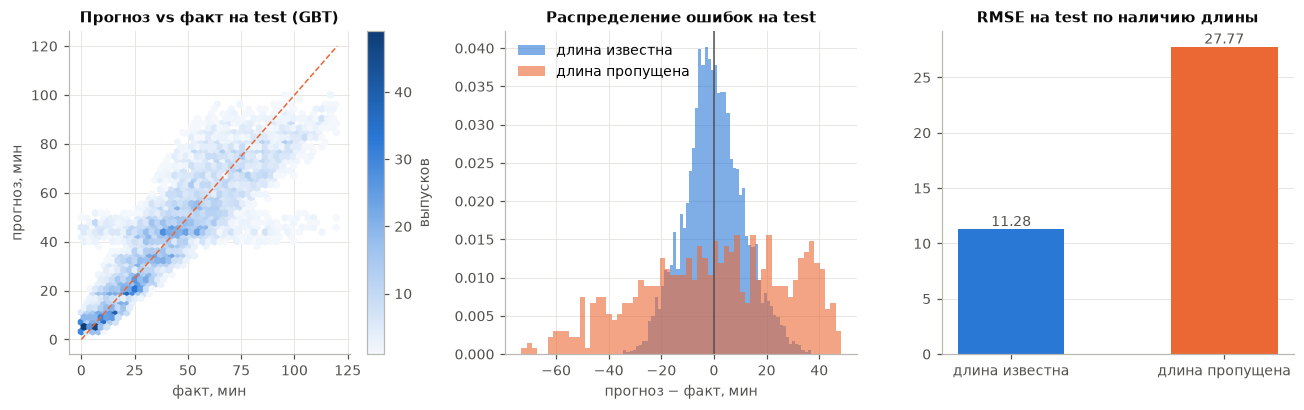

Доля выпусков test без длины: 10.2 %


In [23]:
res = pod_test_pred[FINAL_POD].select("label", "prediction", "length_missing").toPandas()
res["error"] = res.prediction - res.label

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
hb = axes[0].hexbin(res.label, res.prediction, gridsize=45, cmap=SEQ, mincnt=1)
axes[0].plot([0, 120], [0, 120], color=C2, lw=1, ls="--")
axes[0].set_xlabel("факт, мин"); axes[0].set_ylabel("прогноз, мин")
axes[0].set_title(f"Прогноз vs факт на test ({FINAL_POD})")
fig.colorbar(hb, ax=axes[0], label="выпусков")

for flag, color, lab in [(0, C1, "длина известна"), (1, C2, "длина пропущена")]:
    axes[1].hist(res.loc[res.length_missing == flag, "error"], bins=60, color=color, alpha=0.6,
                 density=True, label=lab)
axes[1].axvline(0, color=INK2, lw=1)
axes[1].set_title("Распределение ошибок на test"); axes[1].set_xlabel("прогноз − факт, мин"); axes[1].legend()

grp = res.groupby("length_missing")["error"].apply(lambda e: np.sqrt((e ** 2).mean()))
axes[2].bar(["длина известна", "длина пропущена"], grp.values, color=[C1, C2], width=0.5)
for i, v in enumerate(grp.values):
    axes[2].text(i, v + 0.3, f"{v:.2f}", ha="center", color=INK2)
axes[2].set_title("RMSE на test по наличию длины"); axes[2].grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

print("Доля выпусков test без длины:", round(res.length_missing.mean() * 100, 1), "%")

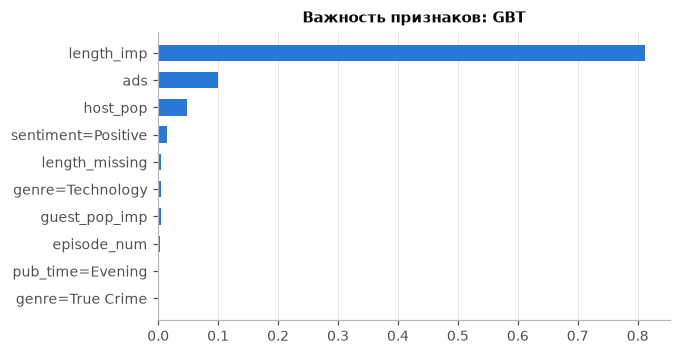

In [24]:
r = best_pod[FINAL_POD]
if r["_prep"] == "linear":
    imp = importances(r["_model"], pod_prep_models["linear"], POD_INPUTS, top=10)
    fig, ax = plt.subplots(figsize=(6, 3.4))
    ax.barh(imp.index[::-1], imp.values[::-1], color=C1, height=0.6)
    ax.set_title(f"Важность признаков: {FINAL_POD}"); ax.grid(axis="y", visible=False)
    plt.show()

**Вывод.** На test, то есть на 7 подкастах, которых модель не видела, GBT показывает RMSE 13,89, MAE 10,32 и R² 0,735 — почти как на valid. Метрика правила k·length — 14,27 / 0,720, константы — 26,98 / 0. Улучшение над правилом невелико (−0,39 мин RMSE). Ошибка почти целиком определяется наличием длины выпуска: при известной длине RMSE равен 11,3 мин, при пропущенной — 27,8 мин, на уровне константы. Модель в этом случае предсказывает около среднего, и распределение ошибок двугорбое (±40 мин). У GBT 81 % важности приходится на длину; дальше идут число реклам и популярность ведущего. Чтобы заметно улучшить прогноз, нужно прежде всего восстанавливать длину выпуска, а не усложнять модель.

# Часть C. Кластеризация: зёрна сухой фасоли (Dry Bean)

**Постановка.** По 16 геометрическим признакам зерна (площадь, периметр, оси, форм-факторы), полученным из
изображения, найти группы похожих зёрен **без использования сорта**. Сорт (`Class`, 7 значений) используется только
после обучения — чтобы проверить, насколько найденные группы соответствуют реальным сортам.

## C.1. Загрузка и Spark-схема

In [25]:
BEAN_NUM = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "AspectRation", "Eccentricity",
            "ConvexArea", "EquivDiameter", "Extent", "Solidity", "roundness", "Compactness",
            "ShapeFactor1", "ShapeFactor2", "ShapeFactor3", "ShapeFactor4"]
bean_schema = StructType([StructField(c, DoubleType(), True) for c in BEAN_NUM] +
                         [StructField("Class", StringType(), True)])
bean_raw = spark.read.option("header", True).schema(bean_schema).csv(str(DATA / "Dry_Bean.csv"))
n_bean = bean_raw.count()
bean = bean_raw.dropDuplicates().cache()
print("Строк:", n_bean, "| полных дублей:", n_bean - bean.count(), "| после удаления:", bean.count())
print("Пропусков всего:", sum(bean.select([F.sum(F.col(c).isNull().cast("int")) for c in bean.columns]).first()))
bean.printSchema()

Строк: 13611 | полных дублей: 68 | после удаления: 13543
Пропусков всего: 0
root
 |-- Area: double (nullable = true)
 |-- Perimeter: double (nullable = true)
 |-- MajorAxisLength: double (nullable = true)
 |-- MinorAxisLength: double (nullable = true)
 |-- AspectRation: double (nullable = true)
 |-- Eccentricity: double (nullable = true)
 |-- ConvexArea: double (nullable = true)
 |-- EquivDiameter: double (nullable = true)
 |-- Extent: double (nullable = true)
 |-- Solidity: double (nullable = true)
 |-- roundness: double (nullable = true)
 |-- Compactness: double (nullable = true)
 |-- ShapeFactor1: double (nullable = true)
 |-- ShapeFactor2: double (nullable = true)
 |-- ShapeFactor3: double (nullable = true)
 |-- ShapeFactor4: double (nullable = true)
 |-- Class: string (nullable = true)



**Вывод.** Прочитано 13 611 зёрен с 16 числовыми признаками и сортом. Удалены 68 полных дублей — вероятно, повторные изображения одного зерна, — осталось 13 543. Пропусков нет.

## C.2. Распределение ключей и схема разбиения

Идентификатора зерна нет; каждое зерно — независимый объект (отдельное изображение). Смотрим распределение
сортов: оно не участвует в обучении, но нужно, чтобы стратифицировать разбиение и затем интерпретировать кластеры.

In [26]:
bean.groupBy("Class").count().withColumn("share_%", F.round(F.col("count") / bean.count() * 100, 1))\
    .orderBy(F.desc("count")).show()

+--------+-----+-------+
|   Class|count|share_%|
+--------+-----+-------+
|DERMASON| 3546|   26.2|
|    SIRA| 2636|   19.5|
|   SEKER| 2027|   15.0|
|   HOROZ| 1860|   13.7|
|    CALI| 1630|   12.0|
|BARBUNYA| 1322|    9.8|
|  BOMBAY|  522|    3.9|
+--------+-----+-------+



## C.3. Train / valid / test

Стратифицированное по сорту разбиение 60 / 20 / 20: модели обучаются на train, число кластеров и алгоритм
выбираются по силуэту на valid, итоговая проверка — на test (на новых зёрнах, не участвовавших в обучении).

In [27]:
bean_train, bean_valid, bean_test = [d.cache() for d in stratified_split(bean, "Class", [0.6, 0.2, 0.2])]
print({k: d.count() for k, d in [("train", bean_train), ("valid", bean_valid), ("test", bean_test)]})

{'train': 8111, 'valid': 2737, 'test': 2695}


## C.4. Распределения признаков

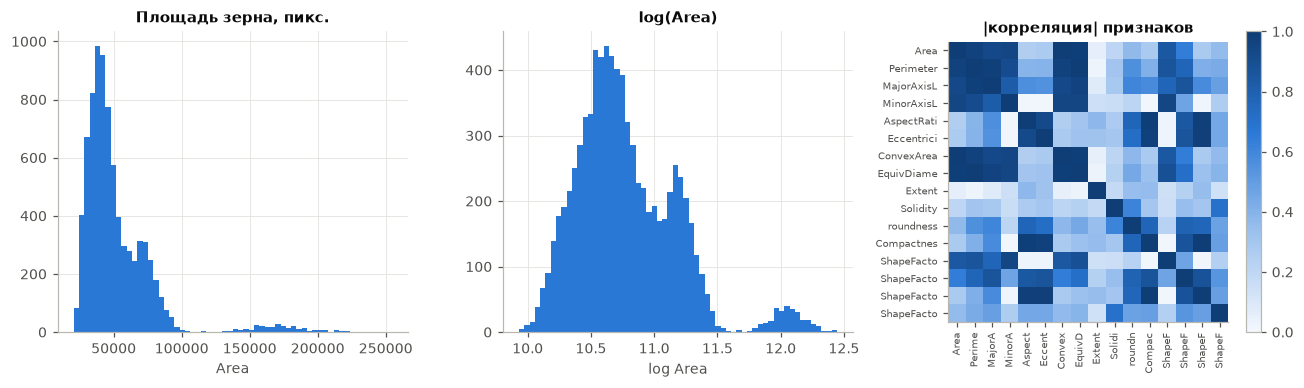

Пар признаков с |r| > 0.95: 13


In [28]:
bpd = bean_train.toPandas()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].hist(bpd.Area, bins=60, color=C1)
axes[0].set_title("Площадь зерна, пикс."); axes[0].set_xlabel("Area")
axes[1].hist(np.log(bpd.Area), bins=60, color=C1)
axes[1].set_title("log(Area)"); axes[1].set_xlabel("log Area")
corr = bpd[BEAN_NUM].corr().abs()
im = axes[2].imshow(corr, cmap=SEQ, vmin=0, vmax=1)
axes[2].set_xticks(range(len(BEAN_NUM)), [c[:6] for c in BEAN_NUM], rotation=90, fontsize=6.5)
axes[2].set_yticks(range(len(BEAN_NUM)), [c[:10] for c in BEAN_NUM], fontsize=6.5)
axes[2].grid(False); axes[2].set_title("|корреляция| признаков")
fig.colorbar(im, ax=axes[2])
fig.tight_layout(); plt.show()

high = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(BEAN_NUM) for b in BEAN_NUM[i + 1:] if corr.loc[a, b] > 0.95]
print("Пар признаков с |r| > 0.95:", len(high))

**Вывод.** Сорта несбалансированы: от DERMASON (26 %) до BOMBAY (3,9 %). Поэтому разбиение 60 / 20 / 20 (8 111 / 2 737 / 2 695) стратифицировано по сорту. Площадь сильно скошена вправо, есть отдельный «хвост» очень крупных зёрен (BOMBAY), после логарифма распределение компактнее. 13 пар признаков связаны с |r| > 0,95 (площадь, выпуклая площадь, периметр, диаметр), то есть описывают одно и то же — размер.

## C.5. Выбор признаков и точки утечки

* `Class` **не входит** в вектор признаков — иначе кластеризация просто воспроизведёт известный ответ,
  а сравнение кластеров с сортами потеряет смысл.
* Размерные признаки (`Area`, `Perimeter`, оси, `ConvexArea`, `EquivDiameter`) имеют правую асимметрию
  и масштаб в тысячи пикселей — они логарифмируются; затем все 16 признаков стандартизуются (`StandardScaler`
  обучается на train). Без масштабирования KMeans фактически кластеризовал бы только по площади.
* Сильно коррелирующие признаки (много пар с |r| > 0,95) оставлены, но для визуализации используется PCA.

In [29]:
SIZE = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "ConvexArea", "EquivDiameter"]
BEAN_FEATS = [f"log_{c}" if c in SIZE else c for c in BEAN_NUM]
bean_prep = Pipeline(stages=[
    SQLTransformer(statement="SELECT *, " + ", ".join(f"log({c}) AS log_{c}" for c in SIZE) + " FROM __THIS__"),
    VectorAssembler(inputCols=BEAN_FEATS, outputCol="raw_features"),
    StandardScaler(inputCol="raw_features", outputCol="features", withMean=True),
]).fit(bean_train)
b_tr, b_va, b_te = [bean_prep.transform(d).cache() for d in (bean_train, bean_valid, bean_test)]
print("Размер вектора:", len(b_tr.first().features))

Размер вектора: 16


## C.6. Модели, базовое решение и выбор числа кластеров на valid

* **Базовое решение:** правило «по размеру» — разбить зёрна на k групп по квантилям площади train (одномерная
  группировка без учёта формы).
* **Модели:** KMeans, BisectingKMeans, GaussianMixture при k = 2…10.
* **Критерий выбора:** максимум силуэта (silhouette, квадрат евклидова расстояния в стандартизованном пространстве)
  на valid **при k ≥ 3**. Разбиение на k = 2 вычисляется и показывается, но в выбор не входит: при двух группах
  зёрна делятся лишь на «крупные / мелкие», что почти совпадает с базовым правилом по площади и не даёт новой
  информации о форме. Дополнительно выводятся ARI с сортом (внешняя проверка, в выборе не участвует) и
  `trainingCost` KMeans (метод «локтя»).

In [30]:
ev_sil = ClusteringEvaluator(featuresCol="features", predictionCol="prediction", metricName="silhouette",
                             distanceMeasure="squaredEuclidean")

def area_rule(df, k):
    qs = bean_train.approxQuantile("Area", [i / k for i in range(1, k)], 0.0001)
    expr = F.lit(0)
    for i, q in enumerate(qs):
        expr = F.when(F.col("Area") > q, i + 1).otherwise(expr)
    return df.withColumn("prediction", expr.cast("int"))

def ari_of(pred):
    p = pred.select("Class", "prediction").toPandas()
    return ari(p.Class, p.prediction)

K_RANGE = range(2, 11)
clu_rows, clu_models = [], {}
for k in K_RANGE:
    rule_pred = area_rule(b_va, k)
    clu_rows.append({"модель": "Правило по площади", "k": k, "silhouette": ev_sil.evaluate(rule_pred),
                     "ARI с сортом": ari_of(rule_pred), "cost": np.nan})
    for name, est in [("KMeans", KMeans(k=k, seed=SEED, maxIter=50)),
                      ("BisectingKMeans", BisectingKMeans(k=k, seed=SEED)),
                      ("GaussianMixture", GaussianMixture(k=k, seed=SEED, maxIter=100))]:
        m = est.fit(b_tr)
        pv = m.transform(b_va)
        cost = m.summary.trainingCost if name == "KMeans" else np.nan
        clu_rows.append({"модель": name, "k": k, "silhouette": ev_sil.evaluate(pv),
                         "ARI с сортом": ari_of(pv), "cost": cost})
        clu_models[(name, k)] = m

clu_table = pd.DataFrame(clu_rows)
clu_table.pivot(index="k", columns="модель", values="silhouette").round(4)

модель,BisectingKMeans,GaussianMixture,KMeans,Правило по площади
k,,,,
2,0.5875,0.5845,0.5875,0.4966
3,0.4549,0.5116,0.5341,0.2759
4,0.4701,0.4108,0.5534,0.1930
5,0.3961,0.2170,0.4801,0.1575
6,0.4371,0.2640,0.4874,0.1038
7,0.4522,0.2565,0.5050,0.0723
8,0.3704,0.1454,0.4294,0.0483
9,0.3249,0.2587,0.4180,0.0191
10,0.3133,0.0685,0.4093,-0.0005


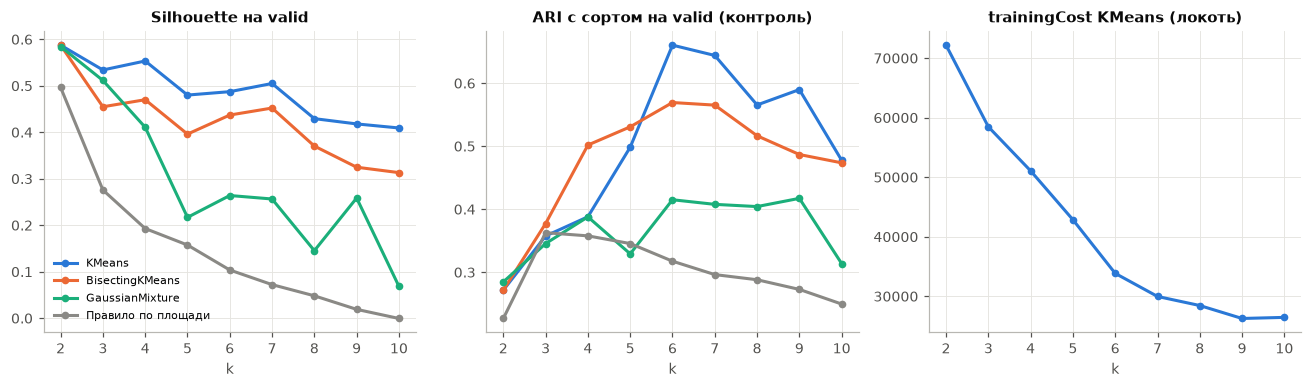

Справочно k = 2 (KMeans): silhouette = 0.5875, ARI = 0.2717
Лучший по silhouette на valid: KMeans, k = 4 (silhouette = 0.5534)


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
models_order = ["KMeans", "BisectingKMeans", "GaussianMixture", "Правило по площади"]
cols = dict(zip(models_order, [C1, C2, C3, "#8a8985"]))
for name in models_order:
    sub = clu_table[clu_table["модель"] == name]
    axes[0].plot(sub.k, sub.silhouette, marker="o", ms=4, color=cols[name], label=name)
    axes[1].plot(sub.k, sub["ARI с сортом"], marker="o", ms=4, color=cols[name], label=name)
km = clu_table[clu_table["модель"] == "KMeans"]
axes[2].plot(km.k, km.cost, marker="o", ms=4, color=C1)
axes[0].set_title("Silhouette на valid"); axes[1].set_title("ARI с сортом на valid (контроль)")
axes[2].set_title("trainingCost KMeans (локоть)")
for ax in axes: ax.set_xlabel("k")
axes[0].legend(fontsize=7.5)
fig.tight_layout(); plt.show()

model_sil = clu_table[(clu_table["модель"] != "Правило по площади") & (clu_table.k >= 3)]
best_row = model_sil.loc[model_sil.silhouette.idxmax()]
k2 = clu_table[(clu_table.k == 2) & (clu_table["модель"] == "KMeans")].iloc[0]
print(f"Справочно k = 2 (KMeans): silhouette = {k2.silhouette:.4f}, ARI = {k2['ARI с сортом']:.4f}")
BEST_CLU, BEST_K = best_row["модель"], int(best_row["k"])
print(f"Лучший по silhouette на valid: {BEST_CLU}, k = {BEST_K} (silhouette = {best_row.silhouette:.4f})")

**Вывод.** Силуэт KMeans выше, чем у других моделей, при всех k ≥ 3. Максимум при k = 2 (0,588) — это деление на крупные и мелкие зёрна, почти как у правила по площади (0,497). Среди k ≥ 3 лучший — KMeans с k = 4 (silhouette 0,553), это локальный максимум. GaussianMixture быстро теряет качество при росте k: в 16-мерном пространстве с сильно коррелирующими признаками он неустойчив. Правило по площади при k ≥ 3 почти бесполезно (силуэт падает до 0). Метод локтя не даёт чёткого перелома, cost равномерно убывает до k ≈ 7. Контрольный ARI с сортами максимален при k = 6–7 (0,66), но в выборе он не участвовал — это внешняя проверка.

## C.7. Оценка на test и интерпретация кластеров

Модели при выбранном `k`, а для сравнения — при k = 2 и k = 7 (число сортов) применяются к test.
Силуэт и ARI считаются на зёрнах, не участвовавших ни в обучении, ни в выборе k.

In [32]:
test_rows = []
for k in sorted({2, BEST_K, 7}):
    rp = area_rule(b_te, k)
    test_rows.append({"модель": "Правило по площади", "k": k, "silhouette": ev_sil.evaluate(rp), "ARI с сортом": ari_of(rp)})
    for name in ["KMeans", "BisectingKMeans", "GaussianMixture"]:
        pt = clu_models[(name, k)].transform(b_te)
        test_rows.append({"модель": name, "k": k, "silhouette": ev_sil.evaluate(pt), "ARI с сортом": ari_of(pt)})
clu_test_table = pd.DataFrame(test_rows).round(4)
clu_test_table

,модель,k,silhouette,ARI с сортом
0,Правило по площади,2,0.4991,0.2351
1,KMeans,2,0.5922,0.2800
2,BisectingKMeans,2,0.5922,0.2800
3,GaussianMixture,2,0.5906,0.2865
4,Правило по площади,4,0.1956,0.3760
5,KMeans,4,0.5614,0.3911
6,BisectingKMeans,4,0.4607,0.5179
7,GaussianMixture,4,0.4175,0.3805
8,Правило по площади,7,0.0602,0.3090
9,KMeans,7,0.5054,0.6670


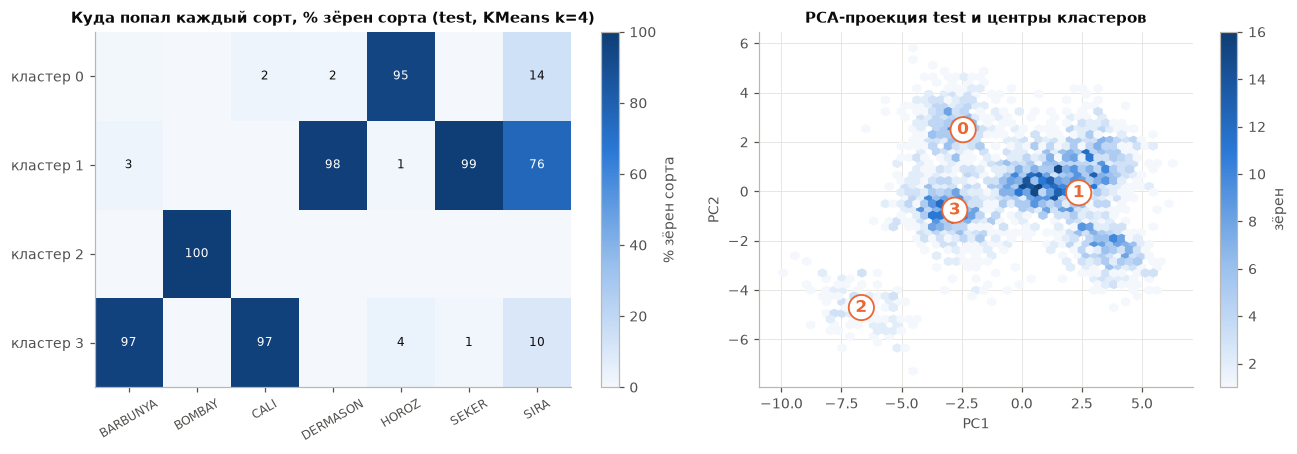

Доля дисперсии, объяснённая PC1+PC2: 83.0 %


In [33]:
final_clu = clu_models[(BEST_CLU, BEST_K)]
pt = final_clu.transform(b_te)
p = pt.select("Class", "prediction", *BEAN_NUM).toPandas()
ct = pd.crosstab(p.prediction, p.Class)
ct_share = (ct.div(ct.sum(axis=0), axis=1) * 100).round(1)

pca = PCA(k=2, inputCol="features", outputCol="pca").fit(b_tr)
xy = np.array(pca.transform(pt).select(vector_to_array("pca").alias("v")).toPandas().v.tolist())
centers = pd.DataFrame(xy).groupby(p.prediction.values).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
im = axes[0].imshow(ct_share.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
for i in range(ct_share.shape[0]):
    for j in range(ct_share.shape[1]):
        v = ct_share.values[i, j]
        if v >= 1:
            axes[0].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 50 else INK)
axes[0].set_xticks(range(ct_share.shape[1]), ct_share.columns, rotation=30, fontsize=8)
axes[0].set_yticks(range(ct_share.shape[0]), [f"кластер {c}" for c in ct_share.index])
axes[0].grid(False); axes[0].set_title(f"Куда попал каждый сорт, % зёрен сорта (test, {BEST_CLU} k={BEST_K})")
fig.colorbar(im, ax=axes[0], label="% зёрен сорта")

hb = axes[1].hexbin(xy[:, 0], xy[:, 1], gridsize=50, cmap=SEQ, mincnt=1)
for c, (cx, cy) in centers.iterrows():
    axes[1].text(cx, cy, str(c), ha="center", va="center", fontsize=11, fontweight="bold", color=C2,
                 bbox=dict(boxstyle="circle,pad=0.25", fc="white", ec=C2, lw=1.2))
axes[1].set_title("PCA-проекция test и центры кластеров"); axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
fig.colorbar(hb, ax=axes[1], label="зёрен")
fig.tight_layout(); plt.show()
print("Доля дисперсии, объяснённая PC1+PC2:", round(float(sum(pca.explainedVariance)) * 100, 1), "%")

In [34]:
profile = (p.groupby("prediction")
           .agg(зёрен=("Class", "size"), Area=("Area", "mean"), AspectRation=("AspectRation", "mean"),
                roundness=("roundness", "mean"), Compactness=("Compactness", "mean"),
                основной_сорт=("Class", lambda s: s.value_counts().index[0]),
                доля_основного=("Class", lambda s: round(s.value_counts().iloc[0] / len(s) * 100, 1)))
           .round(3))
profile

,зёрен,Area,AspectRation,roundness,Compactness,основной_сорт,доля_основного
prediction,,,,,,,
0,444,52097.275,1.970,0.804,0.712,HOROZ,78.8
1,1489,37074.277,1.435,0.914,0.837,DERMASON,46.6
2,112,173385.562,1.592,0.862,0.791,BOMBAY,100.0
3,650,71095.649,1.647,0.827,0.778,CALI,49.1


**Вывод.** На test KMeans с k = 4 даёт силуэт 0,561, а правило по площади — 0,196, то есть модель группирует зёрна с учётом формы, а не только размера. Кластеры содержательные. Кластер 2 — 100 % BOMBAY: очень крупные зёрна, площадь около 173 тыс. пикселей. Кластер 0 объединяет 95 % HOROZ — вытянутые зёрна (AspectRation 1,97, наименьшая округлость). Кластер 3 содержит 97 % BARBUNYA и 97 % CALI — крупные, умеренно вытянутые. Кластер 1 — мелкие округлые зёрна: 98 % DERMASON, 99 % SEKER и 76 % SIRA. ARI при k = 4 равен 0,39, потому что сорта внутри кластеров 1 и 3 похожи по форме и не разделяются. При k = 7 ARI на test растёт до 0,667, но силуэт снижается (0,505): лучшее соответствие сортам достигается ценой менее компактных групп. PCA-проекция (83 % дисперсии) показывает отделённый кластер BOMBAY и плотную область мелких зёрен.

# D. Сохранение моделей

Сохраняется не только обученная модель, а **весь PipelineModel**: подготовка признаков (словари категорий, медианы
`Imputer`, параметры `StandardScaler`, логарифмы) + модель. Порог классификации, выбранное k и версия Spark
записываются отдельно в `model_config.json`. Проверка — загрузка сохранённой модели и повторное применение к test.

In [35]:
air_final = PipelineModel(stages=air_prep_models["FULL"].stages + [best_air[("FULL", FINAL_AIR["FULL"])]["_model"]])
r = best_pod[FINAL_POD]
pod_final = PipelineModel(stages=pod_prep_models[r["_prep"]].stages + [r["_model"]])
bean_final = PipelineModel(stages=bean_prep.stages + [final_clu])

air_final.write().overwrite().save((OUT / "airline_classifier").as_posix())
pod_final.write().overwrite().save((OUT / "podcast_regressor").as_posix())
bean_final.write().overwrite().save((OUT / "bean_clustering").as_posix())

config = {
    "seed": SEED,
    "classification": {"dataset": "Airline Satisfaction", "features": "FULL",
                       "model": FINAL_AIR["FULL"], "params": best_air[("FULL", FINAL_AIR["FULL"])]["параметры"],
                       "threshold": AIR_THRESHOLD},
    "regression": {"dataset": "Podcast", "model": FINAL_POD, "params": r["параметры"],
                   "split": "group by podcast 34/7/7"},
    "clustering": {"dataset": "Dry Bean", "model": BEST_CLU, "k": BEST_K},
    "spark_version": spark.version,
}
(OUT / "model_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(config, ensure_ascii=False, indent=2))

# контроль: загруженная модель даёт тот же результат на test
reloaded = PipelineModel.load((OUT / "airline_classifier").as_posix())
auc_reloaded = ev_roc.evaluate(reloaded.transform(air_test))
print("ROC-AUC загруженной модели на test:", round(auc_reloaded, 4))

{
  "seed": 42,
  "classification": {
    "dataset": "Airline Satisfaction",
    "features": "FULL",
    "model": "RandomForest",
    "params": "maxDepth=18",
    "threshold": 0.51
  },
  "regression": {
    "dataset": "Podcast",
    "model": "GBT",
    "params": "maxDepth=3",
    "split": "group by podcast 34/7/7"
  },
  "clustering": {
    "dataset": "Dry Bean",
    "model": "KMeans",
    "k": 4
  },
  "spark_version": "4.2.1"
}
ROC-AUC загруженной модели на test: 0.9935


# Итоговые выводы

1. **Классификация (Airline).** RandomForest лучше всего предсказывает удовлетворённость по анкете: ROC-AUC 0,994 и F1 0,953 на test. Но это возможно только после опроса. Честный прогноз «до опроса» (класс, цель поездки, тип клиента, задержки) даёт ROC-AUC 0,866 и F1 0,780 — тоже заметно лучше правила (0,766 / 0,740). Разница между этими моделями показывает, сколько качества даёт информация из той же анкеты, что и целевая.
2. **Порог** выбран только на valid (0,51) и перенесён на test без изменений; метрики на valid и test совпадают с точностью до 0,001.
3. **Регрессия (Podcast).** Задача почти линейная: правило «73 % от длины» объясняет 72 % дисперсии на test, лучшая модель (GBT, глубина 3) — 73,5 %. Сложные модели почти ничего не добавляют, а глубокие деревья переобучаются.
4. **Проверка на новых подкастах.** Разбиение по подкастам и удаление дублей до разбиения дают честную оценку переноса на подкасты, которых модель не видела. Качество на test почти не отличается от valid, значит, модель не запоминает конкретные подкасты.
5. **Главный источник ошибки регрессии** — пропущенная длина выпуска: RMSE 27,8 мин против 11,3 при известной длине.
6. **Кластеризация (Dry Bean).** KMeans с k = 4 нашёл осмысленные группы по размеру и форме (BOMBAY, HOROZ, крупные BARBUNYA и CALI, мелкие округлые), а по силуэту на test (0,56 против 0,20) намного лучше правила по площади. Силуэт и соответствие сортам не совпадают: сорта лучше всего воспроизводятся при k = 7, а группы компактнее при k = 2–4.
7. Во всех трёх задачах преобразования (словари категорий, медианы, масштаб) обучались только на train и сохранены вместе с моделями в `results/`. Повторно загруженная модель воспроизводит метрику на test.

**Ограничения**
1. Наборы учебные. Podcast выглядит синтетическим: число рекламных вставок распределено почти поровну между 0–3, у каждого подкаста ровно один жанр, время прослушивания никогда не превышает длину выпуска. Поэтому выводы о поведении слушателей нельзя переносить на реальные подкасты.
2. Гиперпараметры подбирались по небольшой сетке на одном valid, без кросс-валидации. Для RandomForest в классификации оптимум оказался на границе сетки (глубина 18), хотя прирост там уже мал.
3. Оценки сервиса в Airline могут быть следствием удовлетворённости, а не её причиной, поэтому важность признаков нельзя трактовать как причинный эффект.

# Ответы на контрольные вопросы

Вопросы относятся к демонстрационным наборам методички (Online Shoppers, Seoul Bike); ответы даны по их смыслу
с примерами из собственных экспериментов там, где это уместно.

**1. Параметр vs гиперпараметр.** Параметры модель находит при обучении: коэффициенты и intercept LR, пороги и листья
деревьев RF, координаты центров KMeans. Гиперпараметры задаются до обучения: `regParam`, `elasticNetParam` у LR;
`numTrees`, `maxDepth` у RF; `k`, `maxIter`, `seed` у KMeans.

**2. Почему нужен valid, а не только train/test.** Если по test подбирать модель, гиперпараметры и порог, test
перестаёт быть независимой оценкой — результат оптимистично смещён. Valid принимает все решения, test используется
один раз. Кроме того, для временных данных случайное разбиение недопустимо — нужна хронологическая схема.

**3. Утечка данных.** Попадание в признаки информации, недоступной в момент прогноза или прямо производной от цели.
Модель «подсматривает» ответ, метрика очень высокая, но в реальном применении такого признака нет — модель бесполезна
(в части A это оценки сервиса из той же анкеты, что и удовлетворённость).

**4. Browser, Region, TrafficType как категории.** Их числа — коды, а не величины: Region 9 не «больше» Region 2.
Числовая трактовка навязала бы ложный порядок и линейность; поэтому они кодируются one-hot.

**5. Что обучается внутри Pipeline.** `StringIndexer` — словарь категория → индекс (по частоте на train),
`StandardScaler` — средние и стандартные отклонения train, классификатор — свои параметры (коэффициенты, деревья).
Всё это обучается только на train и затем применяется к valid/test.

**6. Accuracy ≈ 0,85 у Online Shoppers.** Покупок около 15 %, поэтому правило «никто не купит» уже даёт accuracy ≈ 0,85.
Метрика не отличает полезную модель от тривиальной; нужны precision/recall, F1, ROC-AUC, PR-AUC.

**7. Порог и precision/recall.** При повышении порога модель реже предсказывает положительный класс: precision обычно
растёт (меньше ложных срабатываний), recall падает (больше пропусков). Это видно на графике выбора порога в A.6.

**8. PR-AUC при редком классе.** ROC-AUC учитывает FPR, который при большом числе отрицательных объектов остаётся малым
даже при многих ложных срабатываниях. PR-AUC строится по precision и recall положительного класса, базовая линия равна
его доле — метрика честно показывает качество поиска редких объектов.

**9. Коэффициенты LR.** Показывают направление и силу связи признака с логарифмом шансов при прочих равных (после
масштабирования — сравнимы между признаками). Это ассоциации в данных: на них влияют корреляции признаков, пропущенные
факторы и обратная причинность, поэтому причинными эффектами они не являются.

**10. Отдельный опыт с PageValues.** PageValues накапливается в ходе сессии и сильно связан с покупкой; если прогноз
нужен в начале сессии, признака ещё нет. Абляция показывает, сколько качества даёт именно он. Момент выдачи прогноза
определяет, какие признаки допустимы (аналогично наборы PRE и FULL в части A).

**11. Functioning Day = No.** В эти часы сервис не работал, число аренд равно нулю по техническим причинам, а не из-за
погоды и спроса. Такие строки — отдельное правило, а не объект регрессии спроса.

**12. sin и cos часа.** Час — циклический признак: 23 и 0 рядом. Пара (sin, cos) переводит час в точку на окружности,
где соседние часы близки; одна только синусоида давала бы одинаковые значения для разных часов.

**13. PolynomialExpansion.** Добавляет квадраты и попарные произведения признаков; модель остаётся линейной по
коэффициентам, но зависимость прогноза от исходных признаков становится нелинейной (кривизна и взаимодействия).

**14. MAE vs RMSE.** MAE — средний модуль ошибки (в единицах цели, устойчив к выбросам); RMSE — корень из среднего
квадрата, сильнее штрафует крупные ошибки. На пики ошибки сильнее реагирует RMSE.

**15. Отрицательный R² на test.** Модель на test хуже, чем константный прогноз средним значением test: она
переобучилась или данные test сдвинуты относительно train.

**16. Среднее по часу как baseline.** Спрос сильно зависит от часа суток; среднее по часу уже улавливает суточный
профиль и даёт гораздо меньшую ошибку, чем глобальное среднее. Модель должна обыгрывать именно его.

**17. day_index.** Порядковый номер дня захватывает тренд внутри одного года, но при переносе на другой год значения
выходят за диапазон train, и модель экстраполирует тренд, которого может не быть.

**18. trainingCost KMeans.** Сумма квадратов расстояний до центров монотонно убывает с ростом k (при k = n она равна
нулю), поэтому минимум cost всегда при максимальном k. Нужны «локоть», силуэт и содержательная интерпретация.

**19. Silhouette.** Близко к +1 — объект ближе к своему кластеру, чем к соседнему; около 0 — на границе кластеров;
отрицательный — объект, вероятно, отнесён не к тому кластеру.

**20. Revenue в кластеризации.** Если включить Revenue в признаки, кластеры частично построятся по факту покупки,
и сравнение «доли покупок по кластерам» станет тавтологией — это утечка цели в признаки (аналогично `Class` в части C).

**21. PCA-проекция.** Две главные компоненты сохраняют лишь часть дисперсии; кластеры, разделённые в 8-мерном
пространстве, могут перекрываться на плоскости и наоборот. Проекция — иллюстрация, а не доказательство.

**22. toPandas().** Только небольшие результаты: агрегаты, таблицы метрик, выборки для графиков, предсказания
небольшого valid/test. Исходные и обучающие данные остаются распределёнными, иначе всё упирается в память драйвера.

**23. Что сохранить вместе с PipelineModel.** Весь конвейер подготовки + модель, а отдельно — порог решения,
выбранные гиперпараметры, k, seed, версию Spark, список признаков и схему входных данных (`model_config.json`).

**24. Различия метрик между версиями Spark.** Допустимы небольшие отличия (единицы в 3-м знаке) из-за изменений
реализации, параллельного порядка вычислений и генераторов случайных чисел. Сильные расхождения (другое число строк,
другой порядок качества, резко иной R² или AUC) указывают на ошибку в данных, разбиении или коде.

In [36]:
for d in [air, air_train, air_valid, air_test, pod, pod_train, pod_valid, pod_test,
          bean, bean_train, bean_valid, bean_test, b_tr, b_va, b_te]:
    d.unpersist()
for dct in [air_tr, air_va, pod_tr, pod_va]:
    for d in dct.values():
        d.unpersist()
spark.stop()
print("SparkSession остановлена; результаты в", OUT.resolve())

SparkSession остановлена; результаты в /Users/nikita/Desktop/Большие данные/5 практика/results
